In [1]:
import pandas as pd
import numpy as np

**Task 1- Data Import and Setup**

In [2]:
data = pd.read_csv("social_media_engagement_5000.csv")

In [3]:
print(data.head())

   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  Female  Brazil   496713     image       fitness   7011.0   
1    10860  33.0    Male  Brazil   157326      reel          food  11750.0   
2    86820  32.0  Female      UK   109864      text          food   4862.0   
3    64886  51.0   Other  France   848877      text       fitness   5350.0   
4    16265  34.0   Other      UK   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count   posted_at  \
0     354.0  1157.0            5726             44650  17-12-2022   
1    2606.0  1807.0            5947             80216  02-06-2023   
2     344.0   955.0            6946             44858  07-05-2023   
3    1083.0  1049.0             229             70455  12-02-2023   
4    2735.0  1300.0            4798              6019  23-05-2023   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      m

In [4]:
print(data.shape)

(5000, 19)


In [5]:
print(data.columns)

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='str')


In [6]:
print(data.tail())

      user_id   age  gender    country  post_id post_type post_category  \
4995    59500  44.0    Male  Australia   441541     video     education   
4996    22100  38.0   Other        UAE   677076      reel     education   
4997    67021  63.0  Female        USA   273595      text        travel   
4998    29800  13.0  Female    Germany   785644     video       fitness   
4999    73400  54.0   Other      Japan   712252      text        travel   

        likes  comments  shares  watch_time_sec  impression_count   posted_at  \
4995  16210.0    2013.0  1837.0            6190             42977  25-06-2022   
4996  16924.0    2734.0  1583.0            7764             34196  18-11-2022   
4997  13487.0       NaN   167.0            7466             23680  06-04-2023   
4998  16894.0    1289.0  1713.0            4991             89013  16-05-2022   
4999  14830.0     503.0  1798.0            3743             14234  04-03-2023   

      follower_count  is_verified device_type sentiment  \
499

In [7]:
print(data.dtypes)

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object


In [8]:
data['posted_at'] = pd.to_datetime(data['posted_at'], dayfirst=True)

In [9]:
print(data['posted_at'].dtype)

datetime64[us]


In [10]:
likes_array = np.array(data['likes'])

print(likes_array)

[ 7011. 11750.  4862. ... 13487. 16894. 14830.]


In [11]:
print("Total values:", len(likes_array))

Total values: 5000


In [12]:
print("Highest likes:", np.max(likes_array))
print("Lowest likes:", np.min(likes_array))

Highest likes: nan
Lowest likes: nan


**Task 2- Data Cleaning**

In [17]:
# Check missing values in the dataset
print(data.isnull().sum())

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [14]:
print(data.isna().sum())

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [15]:
print("Total missing values:", data.isnull().sum().sum())

Total missing values: 900


In [18]:
print(data.isnull().sum())

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [20]:
#Dropna
data_drop = data.dropna()
print(data_drop.shape)

(4162, 19)


In [21]:
#Fillna
data['age'] = data['age'].fillna(data['age'].median())
data['likes'] = data['likes'].fillna(data['likes'].median())
data['comments'] = data['comments'].fillna(data['comments'].median())
data['shares'] = data['shares'].fillna(data['shares'].median())

In [22]:
data['gender'] = data['gender'].fillna(data['gender'].mode()[0])
data['sentiment'] = data['sentiment'].fillna(data['sentiment'].mode()[0])

In [23]:
print(data.isnull().sum())

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


In [25]:
print(data.shape)

(5000, 19)


In [26]:
#Duplicate Handling
print(data.duplicated().sum())

0


In [27]:
print(data[data.duplicated()])

Empty DataFrame
Columns: [user_id, age, gender, country, post_id, post_type, post_category, likes, comments, shares, watch_time_sec, impression_count, posted_at, follower_count, is_verified, device_type, sentiment, hashtags, engagement_rate]
Index: []


In [28]:
data = data.drop_duplicates()
print(data.shape)

(5000, 19)


In [29]:
#Data Formatting
print(data.dtypes)

user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object


In [31]:
data['age'] = data['age'].astype(int)
data['likes'] = data['likes'].round().astype(int)
data['comments'] = data['comments'].astype(int)
data['shares'] = data['shares'].astype(int)

In [32]:
data['gender'] = data['gender'].str.strip().str.title()
data['sentiment'] = data['sentiment'].str.strip().str.lower()

In [33]:
print(data['gender'].unique())
print(data['sentiment'].unique())

<StringArray>
['Female', 'Male', 'Other']
Length: 3, dtype: str
<StringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: str


In [34]:
#Unrealistic Values
print("Negative likes:", (data['likes'] < 0).sum())
print("Negative comments:", (data['comments'] < 0).sum())
print("Negative shares:", (data['shares'] < 0).sum())

Negative likes: 0
Negative comments: 0
Negative shares: 0


In [35]:
print(data[['likes', 'comments', 'shares']].describe())

              likes     comments     shares
count   5000.000000  5000.000000  5000.0000
mean   10106.982400  1502.039800  1002.9106
std     5702.293022   856.393312   570.8552
min       10.000000     0.000000     0.0000
25%     5235.000000   792.000000   511.0000
50%    10105.000000  1497.000000  1012.0000
75%    14959.000000  2235.250000  1483.0000
max    19998.000000  2999.000000  1999.0000


In [36]:
#Feature Cleaning
data['hashtag_count'] = data['hashtags'].str.count('#')
print(data[['hashtags', 'hashtag_count']].head())

                hashtags  hashtag_count
0  #foodie #travel #love              3
1               #fitness              1
2                #foodie              1
3    #music #foodie #fun              3
4                #travel              1


In [37]:
data['sentiment'] = data['sentiment'].str.strip().str.lower()
print(data['sentiment'].unique())

<StringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: str


In [38]:
print(data['sentiment'].value_counts())

sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64


In [39]:
print(data.head())
print(data.shape)


   user_id  age  gender country  post_id post_type post_category  likes  \
0    25795   43  Female  Brazil   496713     image       fitness   7011   
1    10860   33    Male  Brazil   157326      reel          food  11750   
2    86820   32  Female      UK   109864      text          food   4862   
3    64886   51   Other  France   848877      text       fitness   5350   
4    16265   34   Other      UK   449706     image       fitness  12682   

   comments  shares  watch_time_sec  impression_count  posted_at  \
0       354    1157            5726             44650 2022-12-17   
1      2606    1807            5947             80216 2023-06-02   
2       344     955            6946             44858 2023-05-07   
3      1083    1049             229             70455 2023-02-12   
4      2735    1300            4798              6019 2023-05-23   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      mobile  negative  #foodie

**Task 3 - Data Exploration using Pandas**

In [40]:
print(data.head())

   user_id  age  gender country  post_id post_type post_category  likes  \
0    25795   43  Female  Brazil   496713     image       fitness   7011   
1    10860   33    Male  Brazil   157326      reel          food  11750   
2    86820   32  Female      UK   109864      text          food   4862   
3    64886   51   Other  France   848877      text       fitness   5350   
4    16265   34   Other      UK   449706     image       fitness  12682   

   comments  shares  watch_time_sec  impression_count  posted_at  \
0       354    1157            5726             44650 2022-12-17   
1      2606    1807            5947             80216 2023-06-02   
2       344     955            6946             44858 2023-05-07   
3      1083    1049             229             70455 2023-02-12   
4      2735    1300            4798              6019 2023-05-23   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      mobile  negative  #foodie

In [41]:
print(data.tail())

      user_id  age  gender    country  post_id post_type post_category  likes  \
4995    59500   44    Male  Australia   441541     video     education  16210   
4996    22100   38   Other        UAE   677076      reel     education  16924   
4997    67021   63  Female        USA   273595      text        travel  13487   
4998    29800   13  Female    Germany   785644     video       fitness  16894   
4999    73400   54   Other      Japan   712252      text        travel  14830   

      comments  shares  watch_time_sec  impression_count  posted_at  \
4995      2013    1837            6190             42977 2022-06-25   
4996      2734    1583            7764             34196 2022-11-18   
4997      1497     167            7466             23680 2023-04-06   
4998      1289    1713            4991             89013 2022-05-16   
4999       503    1798            3743             14234 2023-03-04   

      follower_count  is_verified device_type sentiment  \
4995          646147       

In [42]:
print("Dataset shape:", data.shape)

Dataset shape: (5000, 20)


In [43]:
print(data.columns)

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='str')


In [44]:
print("Total columns:", len(data.columns))

Total columns: 20


In [45]:
#Datatype and information
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   int64         
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

In [46]:
print(data.dtypes)

user_id                      int64
age                          int64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                        int64
comments                     int64
shares                       int64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
hashtag_count                int64
dtype: object


In [47]:
print(data.isnull().sum())

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
hashtag_count       0
dtype: int64


In [48]:
#Summary statistics
print(data.describe())

            user_id          age        post_id         likes     comments  \
count   5000.000000  5000.000000    5000.000000   5000.000000  5000.000000   
mean   54561.890800    38.440400  548042.909000  10106.982400  1502.039800   
min    10055.000000    13.000000  100068.000000     10.000000     0.000000   
25%    32309.500000    26.000000  322543.500000   5235.000000   792.000000   
50%    54374.500000    38.000000  548077.500000  10105.000000  1497.000000   
75%    77180.500000    51.000000  771574.500000  14959.000000  2235.250000   
max    99963.000000    64.000000  999455.000000  19998.000000  2999.000000   
std    26090.370121    14.687151  260646.957267   5702.293022   856.393312   

          shares  watch_time_sec  impression_count  \
count  5000.0000     5000.000000       5000.000000   
mean   1002.9106     4014.503200      50013.732800   
min       0.0000        0.000000        105.000000   
25%     511.0000     2017.750000      24988.250000   
50%    1012.0000     4034.5

In [49]:
print(data[['likes', 'comments', 'shares']].describe())

              likes     comments     shares
count   5000.000000  5000.000000  5000.0000
mean   10106.982400  1502.039800  1002.9106
std     5702.293022   856.393312   570.8552
min       10.000000     0.000000     0.0000
25%     5235.000000   792.000000   511.0000
50%    10105.000000  1497.000000  1012.0000
75%    14959.000000  2235.250000  1483.0000
max    19998.000000  2999.000000  1999.0000


In [53]:
print(data.describe(include=['object','string']))

       gender country post_type post_category device_type sentiment hashtags
count    5000    5000      5000          5000        5000      5000     5000
unique      3      10         4             8           3         3      761
top      Male   India      reel       fitness      mobile  positive    #tech
freq     1849     535      1283           675        1684      2513      201


In [54]:
#Analyse Categorical Data
print(data['gender'].value_counts())

gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64


In [55]:
print(data['post_type'].value_counts())

post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64


In [56]:
print(data['post_category'].unique())

<StringArray>
[  'fitness',      'food',      'tech',    'travel',   'fashion', 'lifestyle',
 'education',     'music']
Length: 8, dtype: str


In [57]:
print("Total post categories:", data['post_category'].nunique())

Total post categories: 8


In [58]:
print(data['sentiment'].value_counts())

sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64


In [59]:
#Correlation Matrix
correlation = data.corr(numeric_only=True)
print(correlation)

                   user_id       age   post_id     likes  comments    shares  \
user_id           1.000000 -0.006688  0.020051  0.025811 -0.033395  0.013763   
age              -0.006688  1.000000 -0.013153 -0.036323 -0.007284  0.013871   
post_id           0.020051 -0.013153  1.000000  0.014526 -0.010540  0.001846   
likes             0.025811 -0.036323  0.014526  1.000000 -0.018421  0.004712   
comments         -0.033395 -0.007284 -0.010540 -0.018421  1.000000  0.006142   
shares            0.013763  0.013871  0.001846  0.004712  0.006142  1.000000   
watch_time_sec   -0.016847  0.005542  0.018374  0.008710 -0.016351  0.014658   
impression_count  0.015326  0.013322 -0.007709  0.007952 -0.009395 -0.005204   
follower_count    0.010124 -0.024894 -0.002844 -0.022982 -0.011733 -0.010783   
is_verified       0.004058 -0.000079  0.025208 -0.016199 -0.012398  0.007025   
engagement_rate  -0.004282  0.008039  0.010139  0.093521  0.000051  0.021724   
hashtag_count    -0.013692  0.007173  0.

In [60]:
#Groupby
print(data.groupby('post_type')['likes'].mean())

post_type
image    10104.852446
reel     10037.784879
text     10100.132530
video    10188.586122
Name: likes, dtype: float64


In [61]:
print(data.groupby('country')['impression_count'].sum())

country
Australia    23834767
Brazil       24793360
Canada       24984716
France       25656926
Germany      23816649
India        28067377
Japan        23418816
UAE          24610992
UK           25201861
USA          25683200
Name: impression_count, dtype: int64


In [62]:
print(data.groupby('sentiment')['engagement_rate'].mean())

sentiment
negative    1.038486
neutral     0.991170
positive    0.919744
Name: engagement_rate, dtype: float64


In [63]:
print(data.groupby('post_category')['likes'].mean())

post_category
education    10126.472266
fashion       9843.341751
fitness       9914.591111
food         10225.502530
lifestyle    10180.537068
music        10205.737008
tech         10171.560902
travel       10196.290000
Name: likes, dtype: float64


**Task 4 - Data Wrangling**

In [74]:
data['engagement_score'] = data['likes'] + data['comments'] + data['shares']
print(data[['likes', 'comments', 'shares', 'engagement_score']].head())

   likes  comments  shares  engagement_score
0   7011       354    1157              8522
1  11750      2606    1807             16163
2   4862       344     955              6161
3   5350      1083    1049              7482
4  12682      2735    1300             16717


In [75]:
print(data[['engagement_score']].describe())

       engagement_score
count       5000.000000
mean       12611.932800
std         5782.058412
min          193.000000
25%         7807.000000
50%        12551.500000
75%        17478.250000
max        24680.000000


In [76]:
data['log_likes'] = np.log1p(data['likes'])
print(data[['likes', 'log_likes']].head())

   likes  log_likes
0   7011   8.855378
1  11750   9.371694
2   4862   8.489411
3   5350   8.585039
4  12682   9.448018


In [77]:
data['log_impressions'] = np.log1p(data['impression_count'])
print(data[['impression_count', 'log_impressions']].head())

   impression_count  log_impressions
0             44650        10.706632
1             80216        11.292491
2             44858        10.711280
3             70455        11.162744
4              6019         8.702843


In [78]:
print(data.shape)

(5000, 23)


In [79]:
print(data.groupby('post_type')['engagement_score'].mean())

post_type
image    12649.377706
reel     12524.014030
text     12613.228112
video    12664.580408
Name: engagement_score, dtype: float64


In [82]:
print(data.groupby('country')['engagement_score'].mean())

country
Australia    12809.604462
Brazil       12385.972222
Canada       12605.883041
France       12903.370968
Germany      12635.640816
India        12492.678505
Japan        12578.637712
UAE          12757.763419
UK           12384.361055
USA          12575.449102
Name: engagement_score, dtype: float64


In [83]:
print(data.groupby('sentiment')['engagement_score'].mean())

sentiment
negative    12731.483333
neutral     12448.149312
positive    12665.784322
Name: engagement_score, dtype: float64


In [84]:
print(data.groupby('post_type')['engagement_score'].mean().sort_values(ascending=False))

post_type
video    12664.580408
image    12649.377706
text     12613.228112
reel     12524.014030
Name: engagement_score, dtype: float64


In [85]:
print("Engagement by Post Type:")
print(data.groupby('post_type')['engagement_score'].mean())

print("\nEngagement by Country:")
print(data.groupby('country')['engagement_score'].mean())

print("\nEngagement by Sentiment:")
print(data.groupby('sentiment')['engagement_score'].mean())

Engagement by Post Type:
post_type
image    12649.377706
reel     12524.014030
text     12613.228112
video    12664.580408
Name: engagement_score, dtype: float64

Engagement by Country:
country
Australia    12809.604462
Brazil       12385.972222
Canada       12605.883041
France       12903.370968
Germany      12635.640816
India        12492.678505
Japan        12578.637712
UAE          12757.763419
UK           12384.361055
USA          12575.449102
Name: engagement_score, dtype: float64

Engagement by Sentiment:
sentiment
negative    12731.483333
neutral     12448.149312
positive    12665.784322
Name: engagement_score, dtype: float64


In [86]:
#Merge and concat
first_part = data.iloc[:2500]
second_part = data.iloc[2500:]

combined_data = pd.concat([first_part, second_part])

print(combined_data.shape)

(5000, 23)


**Task 5 - Statistical Analysis**

In [87]:
#Mean
columns = ['likes', 'comments', 'shares',
           'watch_time_sec', 'engagement_rate',
           'follower_count']

print(data[columns].mean())

likes               10106.982400
comments             1502.039800
shares               1002.910600
watch_time_sec       4014.503200
engagement_rate         0.964356
follower_count     393698.224800
dtype: float64


In [88]:
#Median
print(data[columns].median())

likes               10105.000000
comments             1497.000000
shares               1012.000000
watch_time_sec       4034.500000
engagement_rate         0.253896
follower_count     388982.000000
dtype: float64


In [89]:
#Mode
print(data[columns].mode().iloc[0])

likes               10105.000000
comments             1497.000000
shares               1012.000000
watch_time_sec        916.000000
engagement_rate         0.006363
follower_count     497502.000000
Name: 0, dtype: float64


In [90]:
#Standarad Deviation
print(data[columns].std())

likes                5702.293022
comments              856.393312
shares                570.855200
watch_time_sec       2308.096459
engagement_rate         5.318029
follower_count     230927.884535
dtype: float64


In [91]:
#Variance
print(data[columns].var())

likes              3.251615e+07
comments           7.334095e+05
shares             3.258757e+05
watch_time_sec     5.327309e+06
engagement_rate    2.828143e+01
follower_count     5.332769e+10
dtype: float64


In [92]:
#Percentiles
print(data[columns].quantile([0.25, 0.50, 0.75]))

        likes  comments  shares  watch_time_sec  engagement_rate  \
0.25   5235.0    792.00   511.0         2017.75         0.145781   
0.50  10105.0   1497.00  1012.0         4034.50         0.253896   
0.75  14959.0   2235.25  1483.0         6020.25         0.504794   

      follower_count  
0.25       194480.00  
0.50       388982.00  
0.75       589744.25  


In [94]:
#Skewness and kurtosis
print("Skewness:")
print(data[columns].skew())

print("Kurtosis:")
print(data[columns].kurt())

Skewness:
likes              -0.006886
comments            0.003802
shares             -0.014654
watch_time_sec     -0.018196
engagement_rate    18.781271
follower_count      0.041118
dtype: float64
Kurtosis:
likes               -1.149992
comments            -1.144375
shares              -1.146857
watch_time_sec      -1.195652
engagement_rate    482.991739
follower_count      -1.189474
dtype: float64


**Task 6 - Data Visualization**

In [95]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

Matplotlib

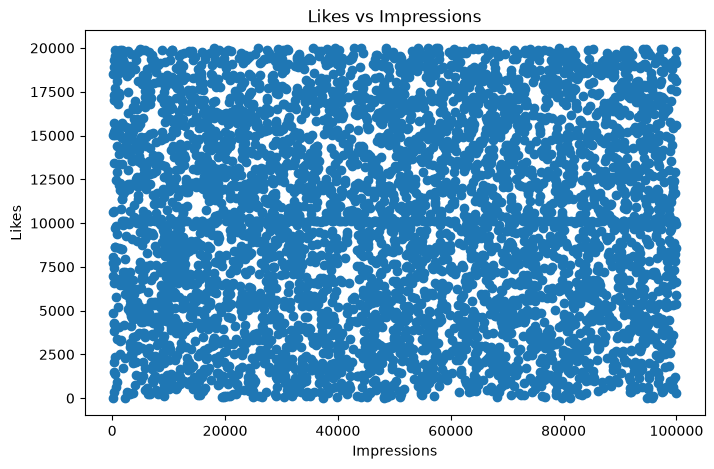

In [96]:
#Scatter Plot
plt.figure(figsize=(8, 5))
plt.scatter(data['impression_count'], data['likes'])
plt.title("Likes vs Impressions")
plt.xlabel("Impressions")
plt.ylabel("Likes")
plt.show()

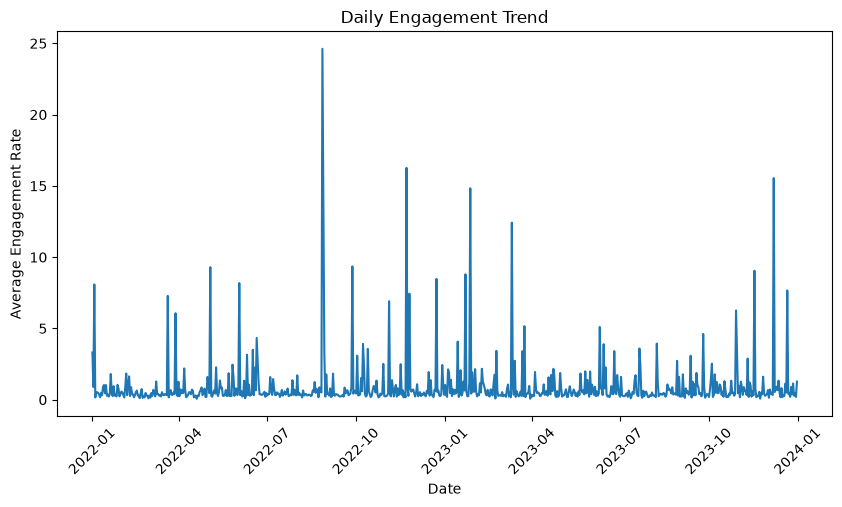

In [108]:
#Line Plot
daily_engagement = data.groupby(data['posted_at'].dt.date)['engagement_rate'].mean()

plt.figure(figsize=(10, 5))
plt.plot(daily_engagement.index, daily_engagement.values)
plt.title("Daily Engagement Trend")
plt.xlabel("Date")
plt.ylabel("Average Engagement Rate")

plt.xticks(rotation=45)
plt.show()

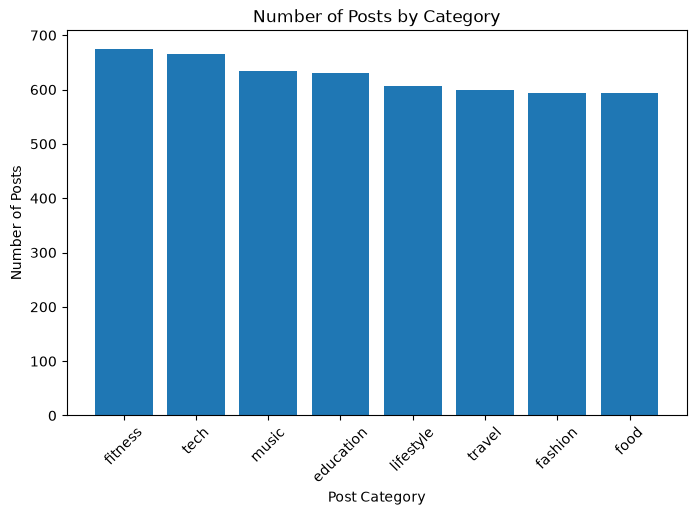

In [102]:
#Bar Plot
post_count = data['post_category'].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(post_count.index, post_count.values)

plt.title("Number of Posts by Category")
plt.xlabel("Post Category")
plt.ylabel("Number of Posts")

plt.xticks(rotation=45)
plt.show()

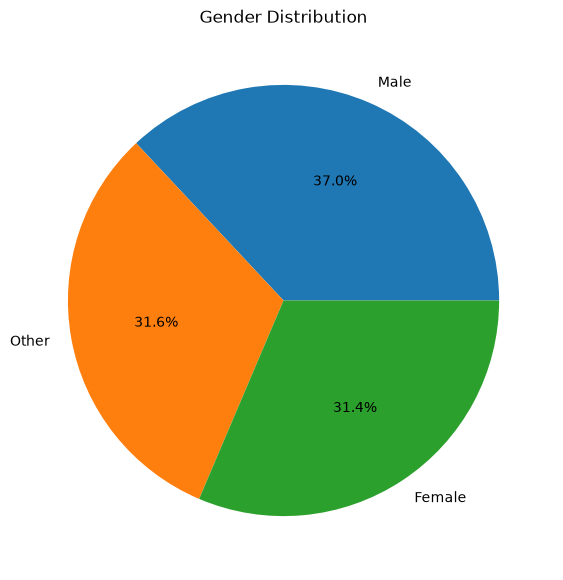

In [103]:
#Pie Chart
gender_count = data['gender'].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(gender_count.values, labels=gender_count.index, autopct='%1.1f%%')

plt.title("Gender Distribution")

plt.show()

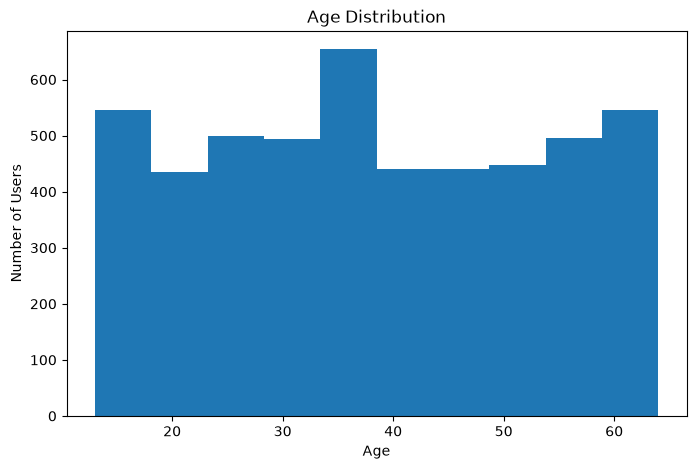

In [104]:
#Histogram
plt.figure(figsize=(8, 5))

plt.hist(data['age'], bins=10)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Users")

plt.show()


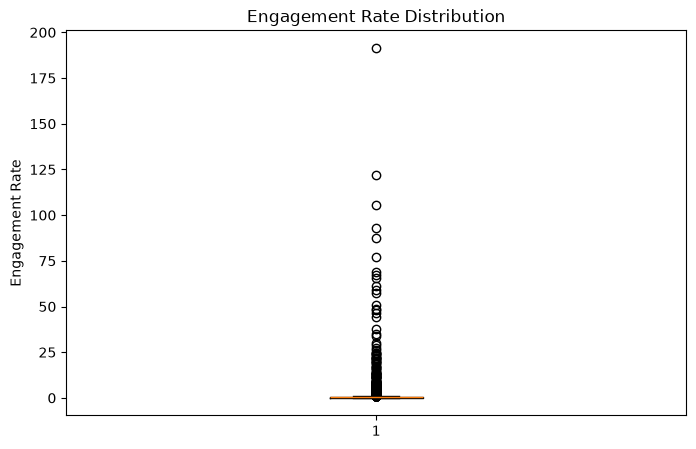

In [106]:
#Box Plot
plt.figure(figsize=(8, 5))

plt.boxplot(data['engagement_rate'])

plt.title("Engagement Rate Distribution")
plt.ylabel("Engagement Rate")

plt.show()

Seaborn

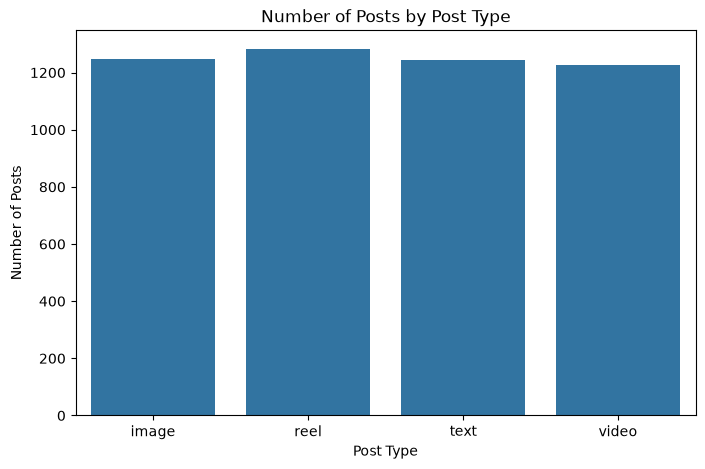

In [109]:
#Count Plot
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x='post_type')

plt.title("Number of Posts by Post Type")
plt.xlabel("Post Type")
plt.ylabel("Number of Posts")

plt.show()

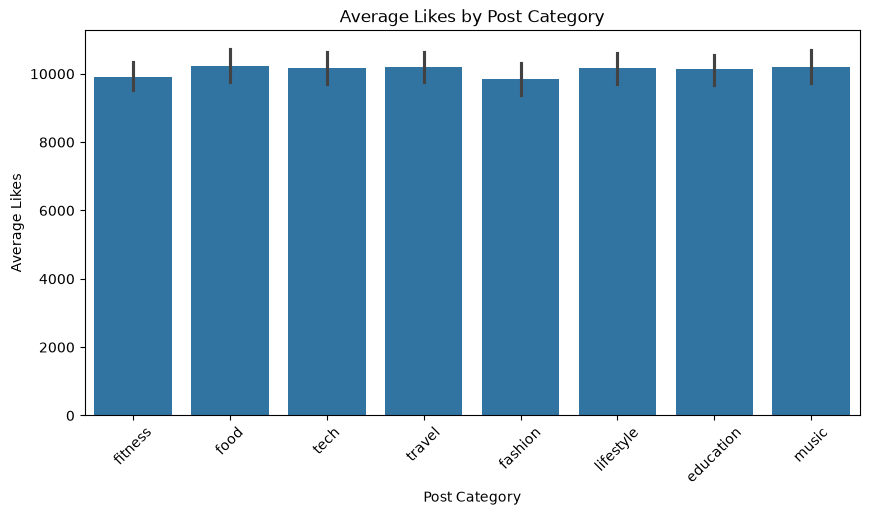

In [110]:
#Bar Plot
plt.figure(figsize=(10, 5))
sns.barplot(data=data, x='post_category', y='likes')

plt.title("Average Likes by Post Category")
plt.xlabel("Post Category")
plt.ylabel("Average Likes")

plt.xticks(rotation=45)
plt.show()

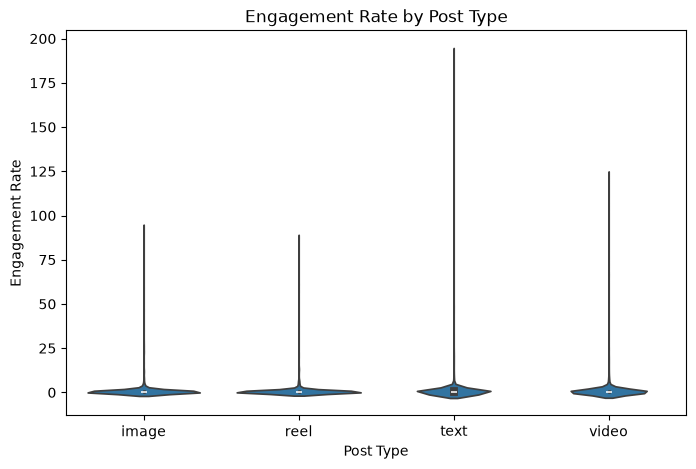

In [116]:
#Violin Plot
plt.figure(figsize=(8, 5))

sns.violinplot(data=data, x='post_type', y='engagement_rate')

plt.title("Engagement Rate by Post Type")
plt.xlabel("Post Type")
plt.ylabel("Engagement Rate")

plt.show()

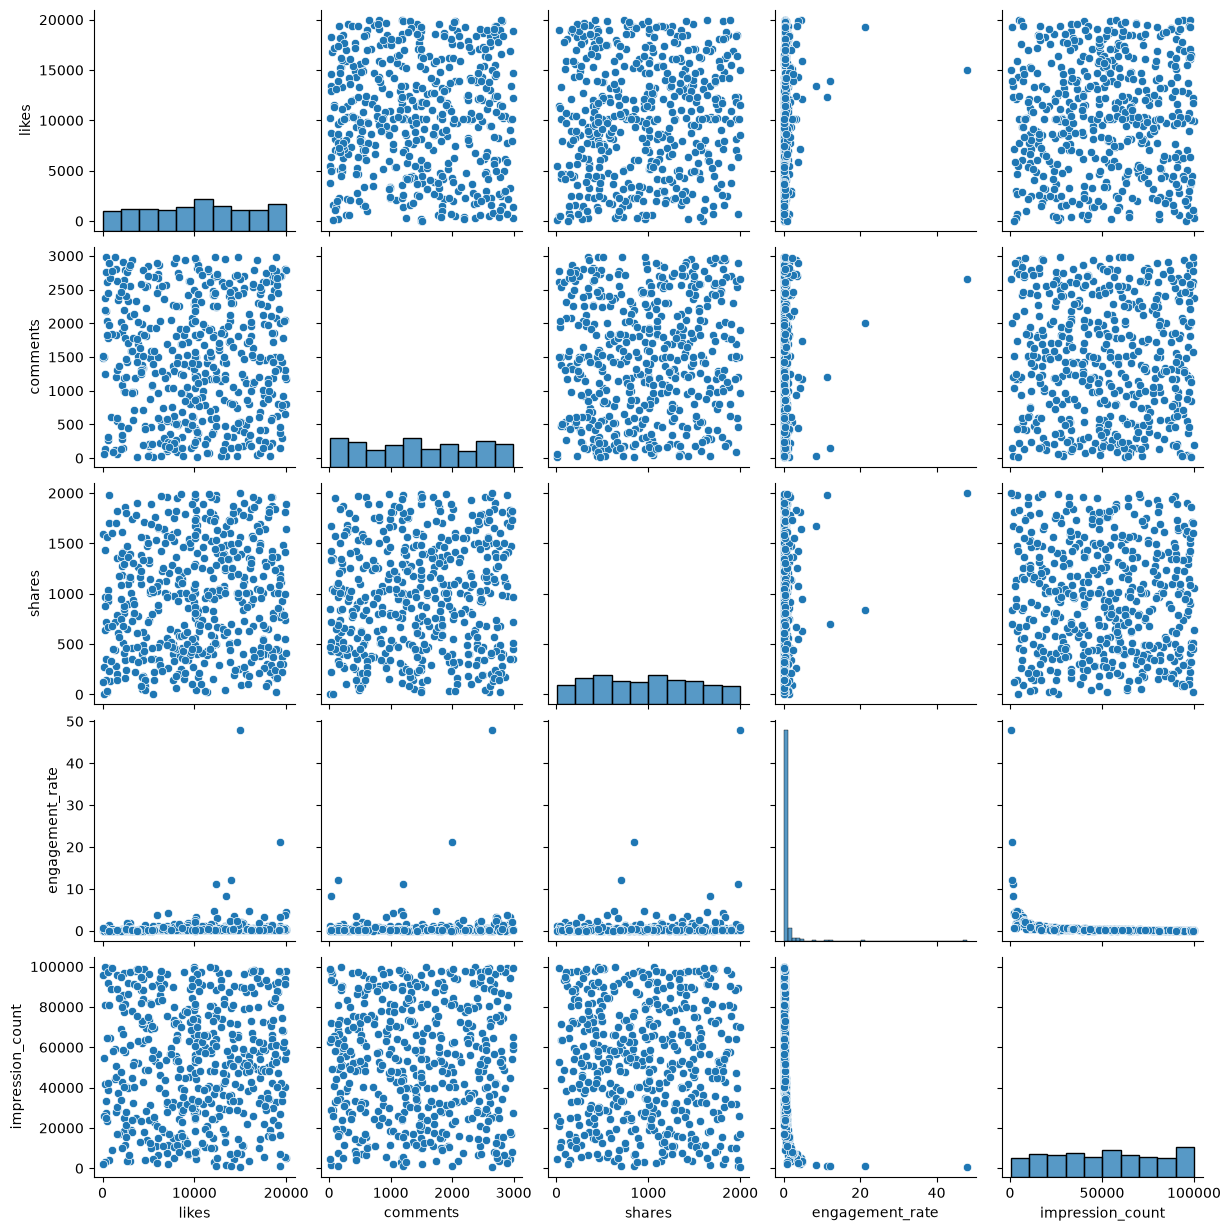

In [117]:
#Pair Plot
sns.pairplot(data[['likes', 'comments', 'shares',
                   'engagement_rate', 'impression_count']].sample(500))

plt.show()

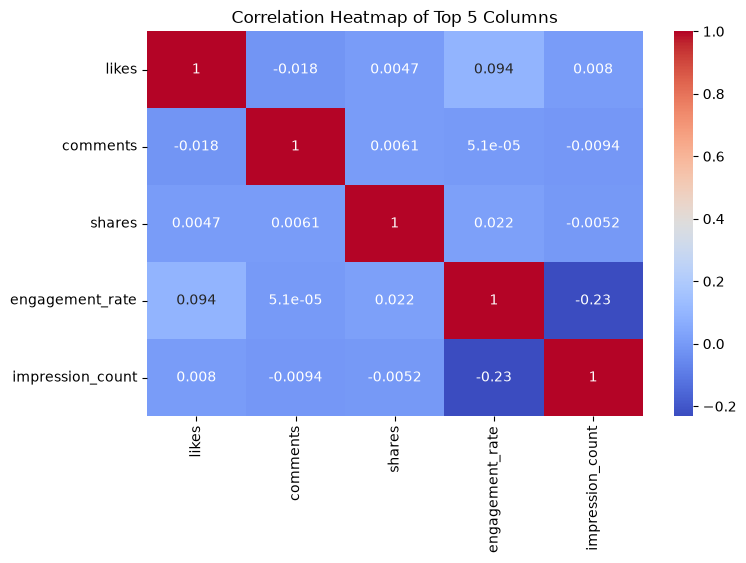

In [114]:
#Heatmap
plt.figure(figsize=(8, 5))

correlation = data[['likes', 'comments', 'shares',
                    'engagement_rate', 'impression_count']].corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap of Top 5 Columns")

plt.show()

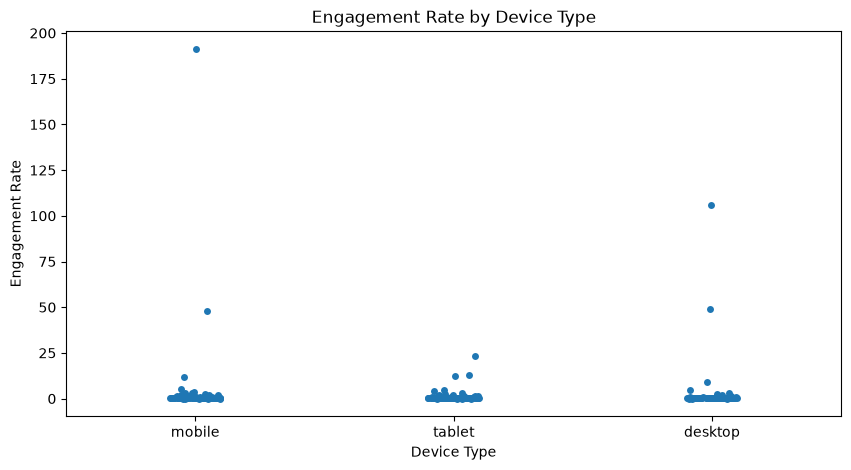

In [133]:
plt.figure(figsize=(10, 5))

sns.stripplot(data=data.sample(300),x='device_type', y='engagement_rate')

plt.title("Engagement Rate by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Engagement Rate")

plt.show()

Plotly

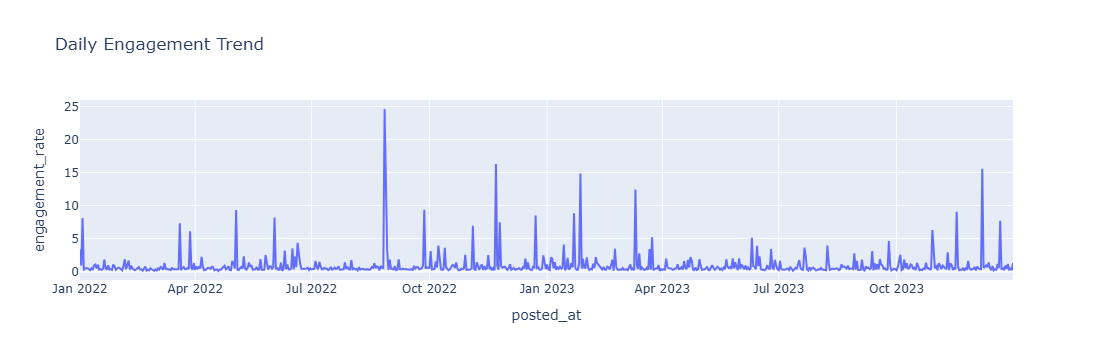

In [136]:
#Line Chart
daily_data = data.groupby(data['posted_at'].dt.date)['engagement_rate'].mean().reset_index()

fig = px.line(daily_data,
              x='posted_at',
              y='engagement_rate',
              title='Daily Engagement Trend')

fig.show()

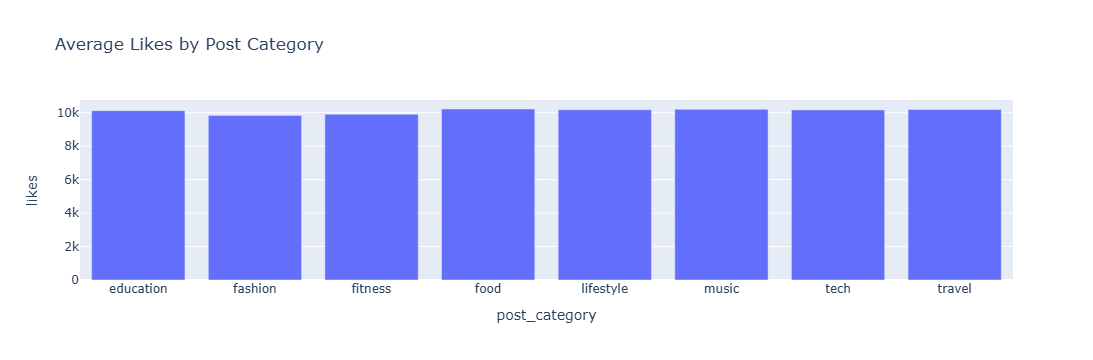

In [137]:
#Bar Chart
category_likes = data.groupby('post_category')['likes'].mean().reset_index()

fig = px.bar(category_likes,
             x='post_category',
             y='likes',
             title='Average Likes by Post Category')

fig.show()

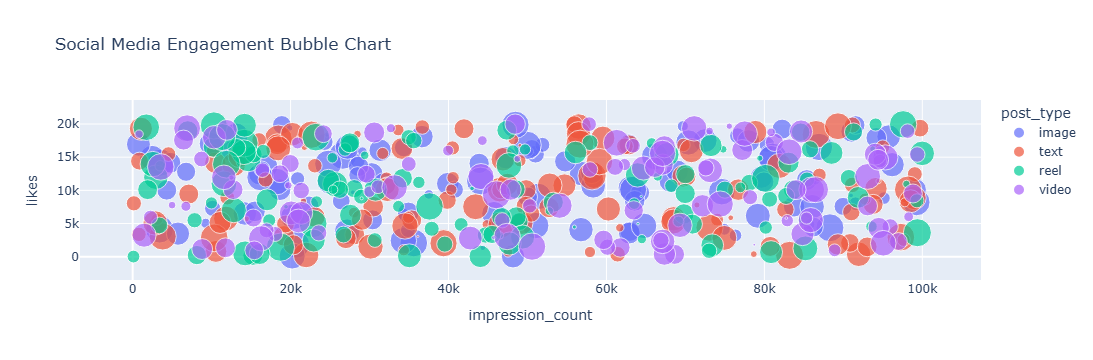

In [138]:
#Bubble Chart
fig = px.scatter(data.sample(500),
                 x='impression_count',
                 y='likes',
                 size='comments',
                 color='post_type',
                 title='Social Media Engagement Bubble Chart')

fig.show()

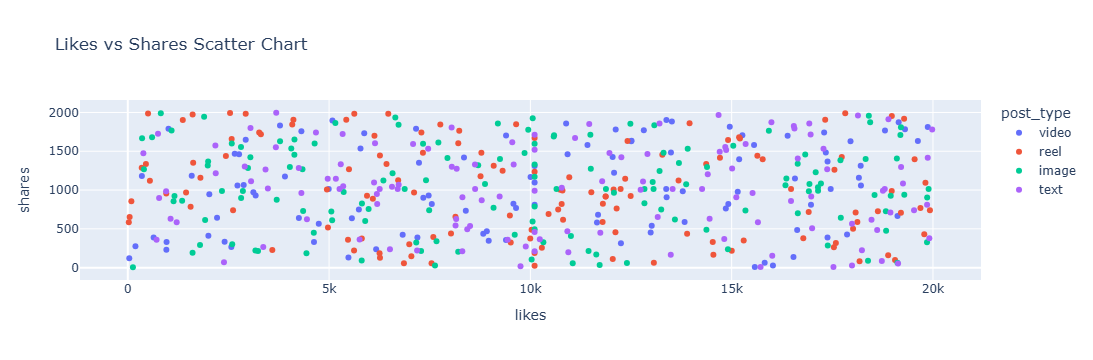

In [142]:
#Scatter Chart
fig = px.scatter(
    data.sample(500),
    x='likes',
    y='shares',
    color='post_type',
    title='Likes vs Shares Scatter Chart'
)

fig.show()

**Final Insights**

    Content performance

In [143]:
#1. Enagagement by post type
post_engagement = data.groupby('post_type')['engagement_score'].mean()

print(post_engagement.sort_values(ascending=False))

post_type
video    12664.580408
image    12649.377706
text     12613.228112
reel     12524.014030
Name: engagement_score, dtype: float64


Video have highest engagement


In [144]:
#2. Best perfoerming content category
category_engagement = data.groupby('post_category')['engagement_score'].mean()
print(category_engagement.sort_values(ascending=False))

post_category
music        12788.537008
food         12739.180438
tech         12686.479699
travel       12650.545000
lifestyle    12639.517298
education    12578.255151
fitness      12457.780741
fashion      12356.405724
Name: engagement_score, dtype: float64


Music is best performing content category


In [145]:
#3.Highest avg engagement rate
country_engagement = data.groupby('country')['engagement_rate'].mean()
print(country_engagement.sort_values(ascending=False))

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64


Brazil have highest average engagement type

User Trends

In [154]:
#Age affects engagement
age_engagement = data.groupby('age')['engagement_score'].mean()
print(age_engagement)

age
13    12718.024390
14    13469.000000
15    12830.104651
16    12235.681818
17    14156.444444
18    12474.918367
19    11867.042553
20    13075.753086
21    12447.333333
22    12528.011628
23    12171.852273
24    13018.568627
25    13195.330189
26    11890.565217
27    12399.967742
28    12126.420561
29    13177.794118
30    13016.389831
31    13279.247191
32    13116.282609
33    13796.258065
34    12670.458824
35    12297.881818
36    13468.504950
37    11828.000000
38    13245.196970
39    13462.839506
40    11824.778947
41    12096.708333
42    12378.850000
43    12937.727273
44    12290.873563
45    12975.322222
46    12213.213483
47    11428.472527
48    12722.216867
49    14162.177778
50    13418.229885
51    12304.727273
52    12418.386364
53    11328.041096
54    12102.808696
55    11626.053763
56    12817.303030
57    12276.825243
58    11843.674419
59    11879.279070
60    12134.571429
61    12446.875000
62    12470.057471
63    12322.438202
64    12081.855670
Name: en

In [148]:
#Performance difference
verified_engagement = data.groupby('is_verified')['engagement_rate'].mean()
print(verified_engagement)

is_verified
False    0.954744
True     1.054250
Name: engagement_rate, dtype: float64


**Behavioral Insights**

In [149]:
#Best time of ady for impression
data['post_hour'] = data['posted_at'].dt.hour

hourly_impressions = data.groupby('post_hour')['impression_count'].mean()

print(hourly_impressions.sort_values(ascending=False))

post_hour
0    50013.7328
Name: impression_count, dtype: float64


In [150]:
#Device type v/s watch time
device_watch_time = data.groupby('device_type')['watch_time_sec'].mean()
print(device_watch_time.sort_values(ascending=False))

device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64


**Sentiment Analysis**

In [152]:
#Engagemnent by  sentiment
sentiment_engagement = data.groupby('sentiment')['engagement_score'].mean()
print(sentiment_engagement.sort_values(ascending=False))

sentiment
negative    12731.483333
positive    12665.784322
neutral     12448.149312
Name: engagement_score, dtype: float64


In [153]:
#Negative and neutral post
negative_neutral = data[data['sentiment'].isin(['negative', 'neutral'])]
print(negative_neutral.groupby('sentiment')[['likes', 'comments', 'shares', 'engagement_score']].mean())

                  likes     comments       shares  engagement_score
sentiment                                                          
negative   10208.081250  1516.094792  1007.307292      12731.483333
neutral     9923.180092  1528.404060   996.565160      12448.149312
